
# Logistic Regression and KNN with Python

We will be working with the [Titanic Data Set from Kaggle](https://www.kaggle.com/c/titanic). This is a very famous data set and very often is a student's first step in machine learning!

We'll be trying to predict a classification- survival or deceased.
Let's begin our understanding of implementing Logistic Regression in Python for classification.

We'll use a "semi-cleaned" version of the titanic data set, if you use the data set hosted directly on Kaggle, you may need to do some additional cleaning not shown in this lecture notebook.

## Import Libraries
Let's import some libraries to get started!

In [56]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

## The Data

Let's start by reading in the titanic_train.csv file into a pandas dataframe.

In [57]:
train = pd.read_csv('titanic_train.csv')

In [58]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [59]:
train.isna().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


# Exploratory Data Analysis

Let's begin some exploratory data analysis! We'll start by checking out missing data!

## Missing Data

We can use seaborn to create a simple heatmap to see where we are missing data!

<Axes: >

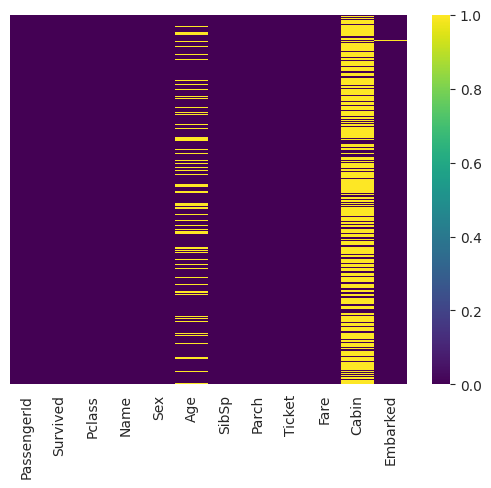

In [60]:
sns.heatmap(train.isnull(),yticklabels=False,cbar=True,cmap='viridis')

Roughly 20 percent of the Age data is missing. The proportion of Age missing is likely small enough for reasonable replacement with some form of imputation. Looking at the Cabin column, it looks like we are just missing too much of that data to do something useful with at a basic level. We'll probably drop this later, or change it to another feature like "Cabin Known: 1 or 0"

Let's continue on by visualizing some more of the data! Check out the video for full explanations over these plots, this code is just to serve as reference.

/tmp/ipykernel_1164/1555596437.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Survived',data=train,palette='RdBu_r')


<Axes: xlabel='Survived', ylabel='count'>

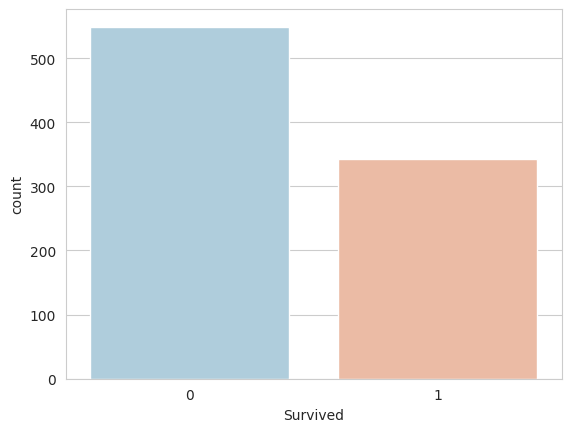

In [61]:
sns.set_style('whitegrid')
sns.countplot(x='Survived',data=train,palette='RdBu_r')

<Axes: xlabel='Survived', ylabel='count'>

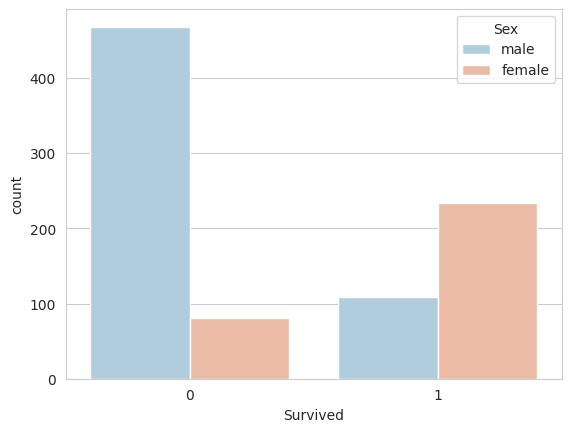

In [62]:
sns.set_style('whitegrid')
sns.countplot(x='Survived',hue='Sex',data=train,palette='RdBu_r')

/tmp/ipykernel_1164/22686760.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(train['Age'].dropna(),kde=True,color='darkred',bins=50)


<Axes: xlabel='Age', ylabel='Density'>

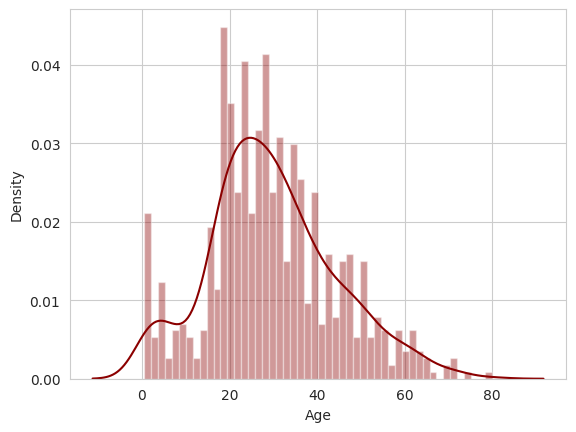

In [63]:
sns.distplot(train['Age'].dropna(),kde=True,color='darkred',bins=50)

<Axes: >

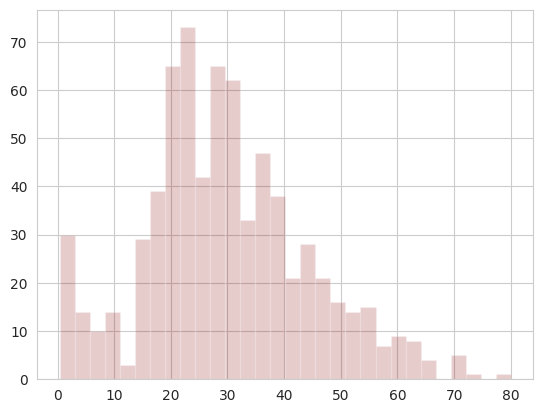

In [64]:
train['Age'].hist(bins=30,color='darkred',alpha=0.2)

<Axes: xlabel='SibSp', ylabel='count'>

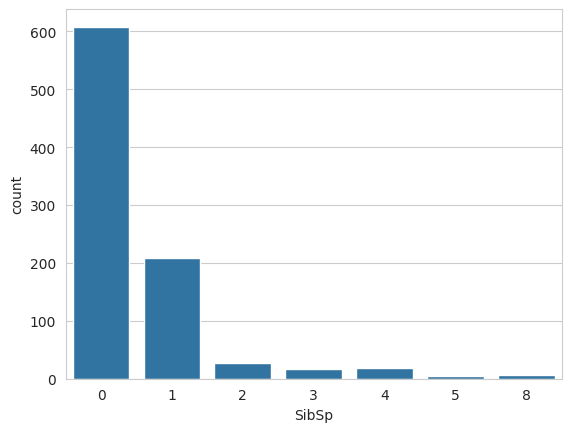

In [65]:
sns.countplot(x='SibSp',data=train)

<Axes: >

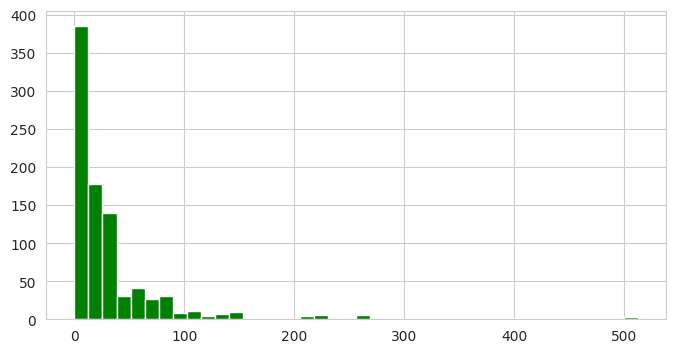

In [66]:
train['Fare'].hist(color='green',bins=40,figsize=(8,4))

___
## Data Cleaning
We want to fill in missing age data instead of just dropping the missing age data rows. One way to do this is by filling in the mean age of all the passengers (imputation).
However we can be smarter about this and check the average age by passenger class. For example:


/tmp/ipykernel_1164/1683851715.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Pclass',y='Age',data=train,palette='winter')


<Axes: xlabel='Pclass', ylabel='Age'>

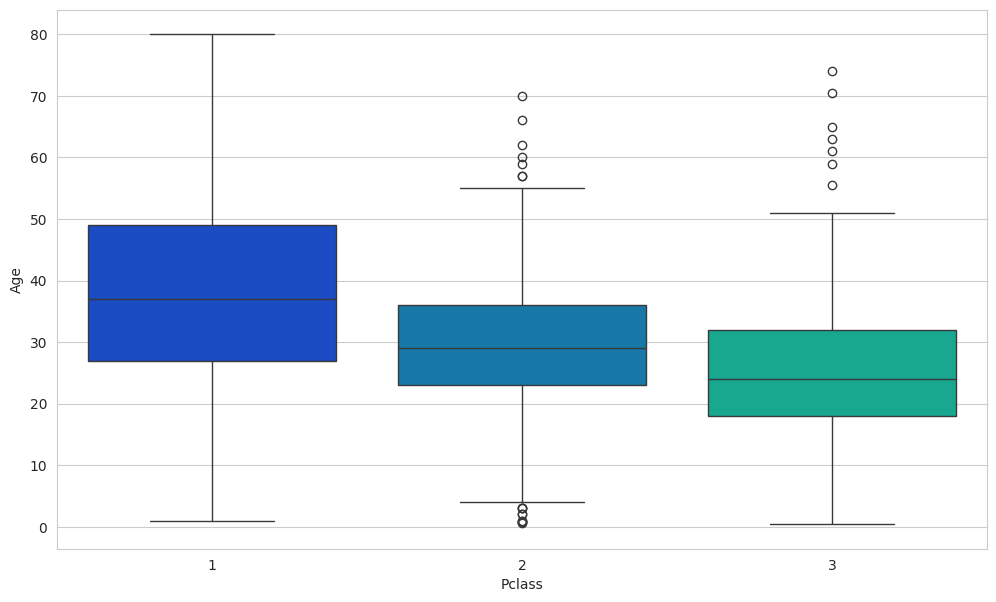

In [67]:
plt.figure(figsize=(12, 7))
sns.boxplot(x='Pclass',y='Age',data=train,palette='winter')

We can see the wealthier passengers in the higher classes tend to be older, which makes sense. We'll use these average age values to impute based on Pclass for Age.

In [68]:
def impute_age(cols):
    Age = cols[0]
    Pclass = cols[1]

    if pd.isnull(Age):

        if Pclass == 1:
            return 37

        elif Pclass == 2:
            return 29

        else:
            return 24

    else:
        return Age

Now apply that function!

In [69]:
train['Age'] = train[['Age','Pclass']].apply(impute_age,axis=1)

/tmp/ipykernel_1164/3438464256.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  Age = cols[0]
/tmp/ipykernel_1164/3438464256.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  Pclass = cols[1]


Now let's check that heat map again!

<Axes: >

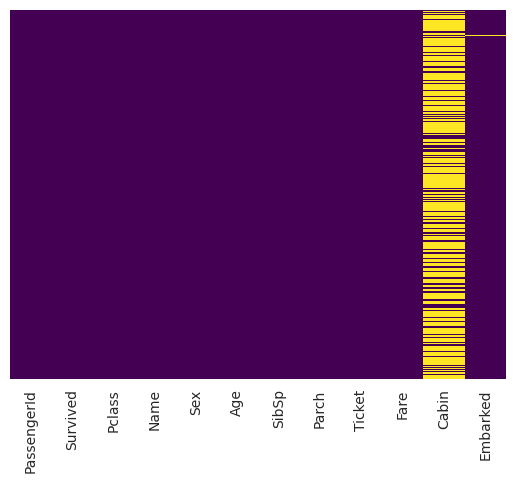

In [70]:
sns.heatmap(train.isnull(),yticklabels=False,cbar=False,cmap='viridis')

<Axes: xlabel='Age'>

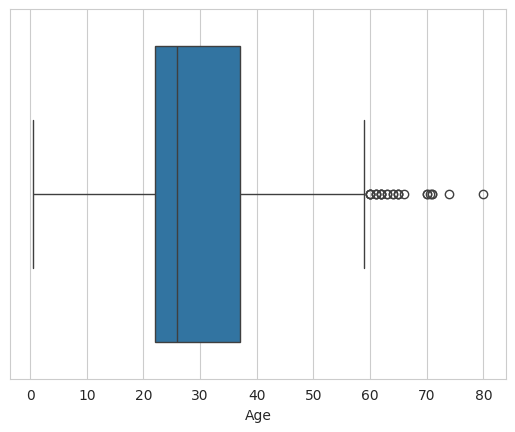

In [71]:
sns.boxplot(x=train['Age'])

<Axes: xlabel='Fare'>

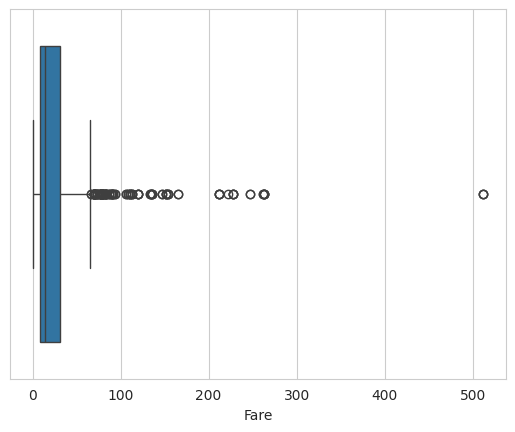

In [72]:
sns.boxplot(x=train['Fare'])

In [73]:
q1 = train['Fare'].quantile(0.25)
q2 = train['Fare'].quantile(0.50)
q3 = train['Fare'].quantile(0.75)
median =  train['Fare'].median()
print("Q1 :",q1)
print("Q2 :",q2)
print("Q3 :",q3)
print("median :",median)

iqr = q3 - q1

upper_tail = q3 + 3*iqr
lower_tail = q1 - 3*iqr
print("Upper Tail :",upper_tail)
print("Lower Tail :",lower_tail)

Q1 : 7.9104
Q2 : 14.4542
Q3 : 31.0
median : 14.4542
Upper Tail : 100.2688
Lower Tail : -61.358399999999996


In [74]:
train[['Fare']].loc[train['Fare'] > upper_tail].shape

(53, 1)

In [75]:
median_fare = train.loc[(train['Fare'] <= upper_tail) &
                            (train['Fare'] >= lower_tail),'Fare'].median()

median_fare

13.0

In [76]:
train.loc[(train['Fare'] > upper_tail) | (train['Fare'] < lower_tail),'Fare'] = median_fare

In [77]:
train.loc[(train['Fare'] > upper_tail) |
                            (train['Fare'] < lower_tail),'Fare']

,Fare


In [78]:
train['Fare']

,Fare
0,7.2500
1,71.2833
2,7.9250
3,53.1000
4,8.0500
...,...
886,13.0000
887,30.0000
888,23.4500
889,30.0000


In [79]:
q1 = train['Age'].quantile(0.25)
q2 = train['Age'].quantile(0.50)
q3 = train['Age'].quantile(0.75)
median =  train['Age'].median()
print("Q1 :",q1)
print("Q2 :",q2)
print("Q3 :",q3)
print("median :",median)

iqr = q3 - q1

upper_tail = q3 + 3*iqr
lower_tail = q1 - 3*iqr
print("Upper Tail :",upper_tail)
print("Lower Tail :",lower_tail)

Q1 : 22.0
Q2 : 26.0
Q3 : 37.0
median : 26.0
Upper Tail : 82.0
Lower Tail : -23.0


In [80]:
median_Age = train.loc[(train['Age'] <= upper_tail) &
                            (train['Age'] >= lower_tail),'Age'].median()

median_Age

26.0

In [81]:
train.loc[(train['Age'] > upper_tail) | (train['Age'] < lower_tail),'Age'] = median_Age

In [82]:
train.loc[(train['Age'] > upper_tail) |
                            (train['Fare'] < lower_tail),'Age']

,Age


In [83]:
train['Age']

,Age
0,22.0
1,38.0
2,26.0
3,35.0
4,35.0
...,...
886,27.0
887,19.0
888,24.0
889,26.0


In [84]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
train[['Age', 'Fare']] = scaler.fit_transform(train[['Age', 'Fare']])


In [85]:
train['Age']

,Age
0,-0.533834
1,0.674891
2,-0.231653
3,0.448255
4,0.448255
...,...
886,-0.156107
887,-0.760469
888,-0.382743
889,-0.231653


In [86]:
train['Fare']

,Fare
0,-0.719010
1,2.434003
2,-0.685772
3,1.538654
4,-0.679617
...,...
886,-0.435878
887,0.401205
888,0.078682
889,0.401205


Great! Let's go ahead and drop the Cabin column and the row in Embarked that is NaN.

In [87]:
train.drop('Cabin',axis=1,inplace=True)

In [88]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,-0.533834,1,0,A/5 21171,-0.719010,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,0.674891,1,0,PC 17599,2.434003,C
2,3,1,3,"Heikkinen, Miss. Laina",female,-0.231653,0,0,STON/O2. 3101282,-0.685772,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,0.448255,1,0,113803,1.538654,S
4,5,0,3,"Allen, Mr. William Henry",male,0.448255,0,0,373450,-0.679617,S


In [89]:
train.isna().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [90]:
train.dropna(inplace=True)

In [91]:
train.isna().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


## Converting Categorical Features

We'll need to convert categorical features to dummy variables using pandas! Otherwise our machine learning algorithm won't be able to directly take in those features as inputs.

In [92]:
train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 889 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  889 non-null    int64  
 1   Survived     889 non-null    int64  
 2   Pclass       889 non-null    int64  
 3   Name         889 non-null    object 
 4   Sex          889 non-null    object 
 5   Age          889 non-null    float64
 6   SibSp        889 non-null    int64  
 7   Parch        889 non-null    int64  
 8   Ticket       889 non-null    object 
 9   Fare         889 non-null    float64
 10  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(4)
memory usage: 83.3+ KB


In [93]:
train=pd.get_dummies(train,columns=['Sex','Embarked'])

In [94]:
train.head()

,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",-0.533834,1,0,A/5 21171,-0.719010,False,True,False,False,True
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0.674891,1,0,PC 17599,2.434003,True,False,True,False,False
2,3,1,3,"Heikkinen, Miss. Laina",-0.231653,0,0,STON/O2. 3101282,-0.685772,True,False,False,False,True
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0.448255,1,0,113803,1.538654,True,False,False,False,True
4,5,0,3,"Allen, Mr. William Henry",0.448255,0,0,373450,-0.679617,False,True,False,False,True


In [95]:
train.drop(['Name','Ticket'],axis=1,inplace=True)

In [96]:
train.head()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,-0.533834,1,0,-0.719010,False,True,False,False,True
1,2,1,1,0.674891,1,0,2.434003,True,False,True,False,False
2,3,1,3,-0.231653,0,0,-0.685772,True,False,False,False,True
3,4,1,1,0.448255,1,0,1.538654,True,False,False,False,True
4,5,0,3,0.448255,0,0,-0.679617,False,True,False,False,True


Great! Our data is ready for our model!

# Building a Logistic Regression model

Let's start by splitting our data into a training set and test set (there is another test.csv file that you can play around with in case you want to use all this data for training).

## Train Test Split

In [97]:
from sklearn.model_selection import train_test_split

In [98]:
X = train.drop('Survived',axis=1)
y = train['Survived']

In [99]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.30,random_state=101)

In [100]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

from sklearn.neighbors import KNeighborsClassifier

In [101]:
normal_scaler = MinMaxScaler()
array = normal_scaler.fit_transform(X_train)
X_train1 = pd.DataFrame(array,columns=X_train.columns)
X_train1.head()

,PassengerId,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,0.906742,1.0,0.236329,0.000,0.0,0.083155,1.0,0.0,0.0,0.0,1.0
1,0.731461,0.5,0.236329,0.000,0.2,0.245989,1.0,0.0,0.0,0.0,1.0
2,0.002247,1.0,0.345425,0.000,0.0,0.084759,1.0,0.0,0.0,0.0,1.0
3,0.775281,0.0,0.413610,0.125,0.0,0.609626,0.0,1.0,0.0,0.0,1.0
4,0.220225,1.0,0.318151,0.000,0.0,0.082888,0.0,1.0,0.0,1.0,0.0


## Training and Predicting

In [102]:
from sklearn.linear_model import LogisticRegression

In [103]:
logmodel = LogisticRegression()
logmodel.fit(X_train,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [104]:
predictions = logmodel.predict(X_test)

Let's move on to evaluate our model!

## Evaluation

We can check precision,recall,f1-score using classification report!

In [105]:
from sklearn.metrics import classification_report, confusion_matrix

In [106]:
print(classification_report(y_test,predictions))

              precision    recall  f1-score   support

           0       0.81      0.90      0.85       163
           1       0.80      0.66      0.73       104

    accuracy                           0.81       267
   macro avg       0.80      0.78      0.79       267
weighted avg       0.80      0.81      0.80       267



In [107]:
print(confusion_matrix(y_test,predictions))

[[146  17]
 [ 35  69]]


In [108]:
knn_clf = KNeighborsClassifier() # Euclidean Distance, k = 5
knn_clf.fit(X_train1,y_train)

KNeighborsClassifier()

In [109]:
x_test_new = pd.DataFrame(normal_scaler.transform(X_test))
x_test_new

,0,1,2,3,4,5,6,7,8,9,10
0,0.574157,1.0,0.318151,0.000,0.0,0.086096,0.0,1.0,0.0,0.0,1.0
1,0.688764,1.0,0.318151,0.000,0.0,0.082888,0.0,1.0,0.0,1.0,0.0
2,0.691011,0.5,0.318151,0.125,0.4,0.695187,1.0,0.0,0.0,0.0,1.0
3,0.378652,0.0,0.549980,0.000,0.0,0.139037,1.0,0.0,1.0,0.0,0.0
4,0.806742,1.0,0.318151,0.000,0.0,0.165775,0.0,1.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
262,0.889888,1.0,0.318151,1.000,0.4,0.743850,1.0,0.0,0.0,0.0,1.0
263,0.930337,1.0,0.318151,0.000,0.0,0.082888,0.0,1.0,0.0,1.0,0.0
264,0.822472,0.5,0.386336,0.000,0.0,0.000000,0.0,1.0,0.0,0.0,1.0
265,0.751685,0.0,0.495432,0.125,0.0,0.556150,1.0,0.0,0.0,0.0,1.0


In [110]:
y_pred = knn_clf.predict(x_test_new)

cnf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix :\n",cnf_matrix)
print("*"*80)


clf_report = classification_report(y_test, y_pred)
print("Classification Report :\n",clf_report)

Confusion Matrix :
 [[144  19]
 [ 28  76]]
********************************************************************************
Classification Report :
               precision    recall  f1-score   support

           0       0.84      0.88      0.86       163
           1       0.80      0.73      0.76       104

    accuracy                           0.82       267
   macro avg       0.82      0.81      0.81       267
weighted avg       0.82      0.82      0.82       267



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(
